> **Business Objective**: Improve property inventory efficiency by increasing the conversion of properties and listings into completed transactions

> **Business Question** : How effectively is the current property inventory being converted into completed transactions?

# Import Library

In [103]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

# Connection to Database

In [104]:
load_dotenv(".env")

conn = create_engine(
    f"postgresql://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)

print("Connection created")

Connection created


# Property and Listing Analysis

## 
Retrive Data

In [105]:
dataset = '''
            SELECT
                l.listing_id
                ,l.agent_id
                ,t.transaction_id
                ,p.property_id
                ,l.listing_date
                ,l.listing_channel
                ,l.listing_status
                ,l.listed_price
                ,l.days_on_market
                ,l.close_date
                ,t.deal_date
                ,t.deal_price
                ,t.deal_status
                ,t.commission_amount
                ,p.city AS prop_city
                ,p.property_type
                ,p.size_sqm
                ,p.bedrooms
                ,p.bathrooms
                ,p.location_score
                ,p.has_parking
                ,p.near_transit
                ,p.near_school
                ,p.list_price
                ,p.amenities_count
            FROM listings l
            FULL OUTER JOIN transactions t ON l.listing_id = t.listing_id
            FULL OUTER JOIN properties p ON l.property_id = p.property_id
            WHERE DATE_PART('year',listing_date)<=2024 OR listing_date IS NULL
            '''
df_dataset = pd.read_sql(dataset,conn)

In [106]:
df_dataset['deal_date'] = pd.to_datetime(df_dataset['deal_date']).astype('datetime64[ns]')
df_dataset['listing_date'] = pd.to_datetime(df_dataset['listing_date']).astype('datetime64[ns]')
df_dataset['close_date'] = pd.to_datetime(df_dataset['close_date']).astype('datetime64[ns]')


bins_price = np.linspace(min(df_dataset['listed_price']),max(df_dataset['listed_price']),4)
category = ['cheap','medium','expensive']
df_dataset['listed_price_cat'] = pd.cut(df_dataset['listed_price'],bins_price,labels=category,include_lowest = True)

bins_size = np.linspace(min(df_dataset['size_sqm']),max(df_dataset['size_sqm']),4)
category = ['small','medium','large']
df_dataset['property_size_cat'] = pd.cut(df_dataset['size_sqm'],bins_size,labels=category,include_lowest = True)

bins_location_score = np.linspace(min(df_dataset['location_score']),max(df_dataset['location_score']),4)
category = ['low','medium','high']
df_dataset['location_score_cat'] = pd.cut(df_dataset['location_score'],bins_location_score,labels=category,include_lowest = True)

##
**Propertiy and Listing Overview**

In [107]:
df_listing = df_dataset[~df_dataset['listing_id'].isna()].reset_index(drop=True)

df_properties = df_dataset.drop_duplicates(subset = 'property_id').sort_values('property_id').reset_index(drop = True)
df_listed_prop = df_properties[~df_properties['listing_id'].isna()].reset_index(drop=True)
df_unlisted_prop = df_properties[df_properties['listing_id'].isna()]

df_transaction = df_dataset[(~df_dataset['transaction_id'].isna()) & ((df_dataset['deal_date'].dt.year)<=2024)].reset_index()
df_trans_prop = df_transaction.drop_duplicates('property_id').reset_index(drop=True)

df_completed = df_transaction[df_transaction['deal_status']=='Completed'].reset_index(drop=True)
df_disputed = df_transaction[df_transaction['deal_status']=='Disputed'].reset_index(drop=True)
df_transaction_prop_completed = df_completed.drop_duplicates(subset ='property_id')
df_transaction_prop_disputed = df_disputed.drop_duplicates(subset='property_id')

In [108]:

df_property_type = (\
    df_dataset
    .groupby('property_type')
    .agg(total_listing = ('listing_id','nunique'),
         total_property = ('property_id','nunique'))
    .reset_index()
)
df_property_type['listing_share'] = (\
    round(
        (df_property_type['total_listing']/
         (df_property_type['total_listing'].sum()))*100,2
    )
)
df_property_type['property_share'] = (\
    round(
        (df_property_type['total_property']/
         (df_property_type['total_property'].sum()))*100,2
    )
)

df_property_type = df_property_type.sort_values('property_share',ascending = False).reset_index(drop=True)


df_city = (\
    df_dataset
        .groupby('prop_city')
        .agg(total_listing = ('listing_id','nunique'),
             total_property = ('property_id','nunique'))
        .reset_index()    
)
df_city['listing_share'] = (\
    round(
        (df_city['total_listing']/
         (df_city['total_listing'].sum()))*100,2
    )
)
df_city['property_share'] = (\
    round(
        (df_city['total_property']/
         (df_city['total_property'].sum()))*100,2
    )
)

df_city = df_city.sort_values('property_share',ascending = False).reset_index()

variabel = {'Listing':df_listing,
               'Property' : df_properties,
               'Listed Property': df_listed_prop,
               'Unlisted Property' : df_unlisted_prop,
               'Transaction' : df_transaction,
               'Completed Transaction' : df_completed,
               'Disputed Transaction': df_disputed,
               'Property Sold': df_transaction_prop_completed} 

print(f'{"-"*20} Properties and Listing Overview {"-"*20}')
for x,y in variabel.items():
    print(f'Number of {x} = {len(y)}')

display(df_property_type)
display(df_city)

-------------------- Properties and Listing Overview --------------------
Number of Listing = 8500
Number of Property = 4500
Number of Listed Property = 3817
Number of Unlisted Property = 683
Number of Transaction = 3776
Number of Completed Transaction = 3737
Number of Disputed Transaction = 39
Number of Property Sold = 2516


,property_type,total_listing,total_property,listing_share,property_share
0,Apartment,4683,2472,55.09,54.93
1,House,2216,1165,26.07,25.89
2,Land,906,492,10.66,10.93
3,Commercial,695,371,8.18,8.24


,index,prop_city,total_listing,total_property,listing_share,property_share
0,2,Dhaka,2527,1308,29.73,29.07
1,1,Chattogram,1575,816,18.53,18.13
2,3,Khulna,959,500,11.28,11.11
3,4,Mymensingh,757,409,8.91,9.09
4,5,Rajshahi,724,408,8.52,9.07
5,6,Rangpur,697,381,8.20,8.47
6,7,Sylhet,649,352,7.64,7.82
7,0,Barishal,612,326,7.20,7.24


##


##
**Property & Listings Conversion**

>What is the property and the listing conversion rate?

In [109]:
conversion_property = (
    round(
        (len(df_transaction_prop_completed)/
         len(df_listed_prop))
        *100,0)
)

conversion_listing = (
    round(
        (len(df_completed)/
         len(df_listing))
         *100,0)
)


print(f'Conversion Rate of Property = {conversion_property}%')
print(f'Conversion Rate of Listing = {conversion_listing}%')

Conversion Rate of Property = 66.0%
Conversion Rate of Listing = 44.0%


##
**Annual Property & Listing Absorption Rate**

>How does property and listing inventory absorption change over time?

###
Annual Listing Absorption Rate

,year,carry_over_listing,new_listing,available_listing,carry_over_completed,new_completed_listing,total_completed_listing,uncompleted_listing,CarOv uncompleted,new_listing_uncompeted,absorption_rate
0,2022,0,2879,2879,0,1121,1121,230,0,230,38.94
1,2023,1514,2771,4285,151,1128,1279,524,327,197,29.85
2,2024,2468,2850,5318,133,1204,1337,845,612,233,25.14


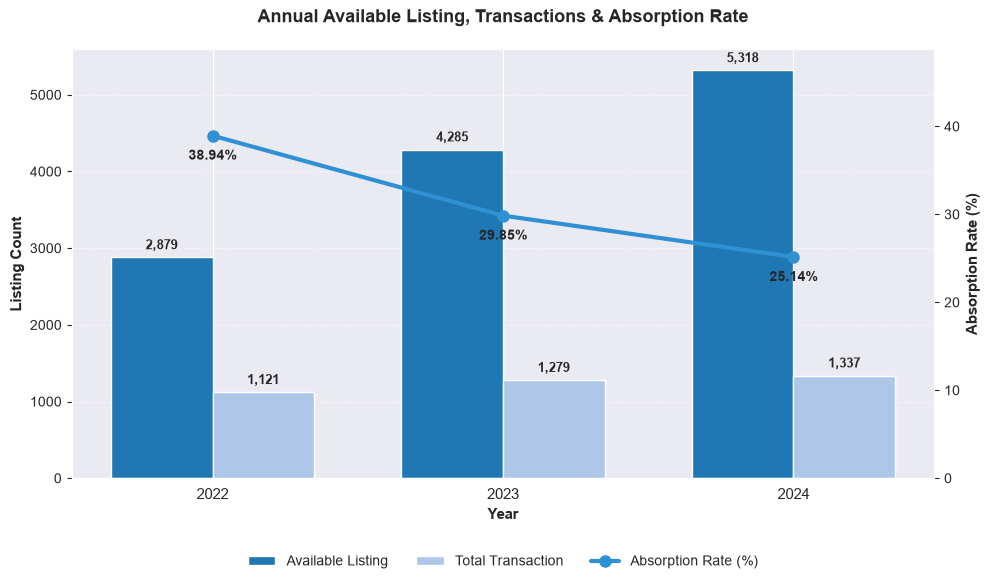

In [110]:
annual_available_listing = []
years = (df_listing['listing_date'].dt.year).unique()

for year in years:
    start_date = pd.Timestamp(f'{year}-01-01')
    end_date = pd.Timestamp(f'{year}-12-31')
    
    carry_over_listing = (
        df_listing[
            (df_listing['listing_date']<start_date) &
            (
                (df_listing['close_date']>=start_date)|
                (df_listing['listing_status']=='Active'))
        ]['listing_id'].unique()
    )
    total_carry_over_listing = len(carry_over_listing)
    
    new_listing = (
        df_listing[
            (df_listing['listing_date']>=start_date)&
            (df_listing['listing_date']<=end_date)
        ]['listing_id'].unique()
    )
    total_new_listing = len(new_listing)

    available_listing = np.union1d(carry_over_listing,new_listing)
    total_available_listing = len(available_listing)

    completed_listing = (
        df_completed[
            (df_completed['deal_date']>=start_date)&
            (df_completed['deal_date']<=end_date)
        ]['listing_id'].unique()
    )
    total_completed_listing = len(completed_listing)

    carry_over_completed_listing = np.intersect1d(carry_over_listing,completed_listing)
    new_completed_listing = np.intersect1d(new_listing,completed_listing)
    total_carov_completed = len(carry_over_completed_listing)
    total_new_completed = len(new_completed_listing)

    uncompleted_listing = (
        df_listing[
            (df_listing['close_date']>=start_date)&
            (df_listing['close_date']<=end_date)&
            (df_listing['deal_date'].isna())]
    )['listing_id'].unique()
    total_uncompleted_listing = len(uncompleted_listing)

    uncompleted_carov_listing = np.intersect1d(carry_over_listing,uncompleted_listing)
    new_uncompleted_listing = np.intersect1d(new_listing,uncompleted_listing)
    total_carov_uncompleted = len(uncompleted_carov_listing)
    total_new_uncompleted = len(new_uncompleted_listing)

    annual_available_listing.append(
        {'year':year,
         'carry_over_listing':total_carry_over_listing,
         'new_listing':total_new_listing,
         'available_listing':total_available_listing,
         'carry_over_completed':total_carov_completed,
         'new_completed_listing':total_new_completed,
         'total_completed_listing':total_completed_listing,
         'uncompleted_listing':total_uncompleted_listing,
         'CarOv uncompleted':total_carov_uncompleted,
         'new_listing_uncompeted':total_new_uncompleted}
    )
      
annual_absorption_rate = pd.DataFrame(annual_available_listing)
annual_absorption_rate['absorption_rate'] = (\
    annual_absorption_rate['total_completed_listing']
    /annual_absorption_rate['available_listing']*100).round(2)

annual_absorption_rate = annual_absorption_rate.sort_values('year').reset_index(drop=True)
display(annual_absorption_rate)


#GRAFIK

sns.set_style("darkgrid")
fig, ax1 = plt.subplots(figsize=(10, 6))

x = np.arange(len(annual_absorption_rate["year"]))
width = 0.35

rects1 = ax1.bar(\
    x - width / 2,
    annual_absorption_rate["available_listing"],
    width,
    label="Available Listing",
    color="#1f77b4",
)

rects2 = ax1.bar(\
    x + width / 2,
    annual_absorption_rate["total_completed_listing"],
    width,
    label="Total Transaction",
    color="#aec7e8",
)

ax1.set_ylabel("Listing Count", fontsize=11, fontweight="bold")
ax1.set_xlabel("Year", fontsize=11, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(annual_absorption_rate["year"].astype(str), fontsize=11)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

for rect in rects1 + rects2:
    height = rect.get_height()
    ax1.annotate(
        f"{int(height):,}",
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

ax2 = ax1.twinx()

line_color = "#2f91d3"

line = ax2.plot(\
    x,
    annual_absorption_rate["absorption_rate"],
    color=line_color,
    marker="o",
    linewidth=3,
    markersize=8,
    label="Absorption Rate (%)",
)

ax2.set_ylabel("Absorption Rate (%)", fontsize=11, fontweight="bold")
ax2.tick_params(axis="y")
ax2.grid(False)

max_rate = annual_absorption_rate["absorption_rate"].max()
ax2.set_ylim(0, max_rate * 1.25)

for i, txt in enumerate(annual_absorption_rate["absorption_rate"]):
    ax2.annotate(\
        f"{txt:.2f}%",
        (x[i], txt),
        textcoords="offset points",
        xytext=(0, -10),
        ha="center",
        va = 'top',
        fontweight="bold",
        fontsize=10,
    )

plt.title(
    "Annual Available Listing, Transactions & Absorption Rate",
    fontsize=13,
    fontweight="bold",
    pad=20,
    loc="center",
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(\
    lines1 + lines2,
    labels1 + labels2,
    bbox_to_anchor=(0.5, -0.15),
    loc="upper center",
    ncol =3,
    frameon=True,
    facecolor="white",
    edgecolor="none",
)

sns.despine(top=True, right=False)
plt.tight_layout()
plt.show()




###
Annual Property Absorption Rate(%)

,year,total_carry_over_property,total_new_property,total_newest_prop,total_resell_prop,total_available_property,total_completed_property,total_prop_multiple trans,absorption_rate
0,2022,0,2133,2133,0,2133,993,119,46.55
1,2023,1283,1452,1079,373,2735,1099,157,40.18
2,2024,1814,1259,605,654,3073,1161,163,37.78


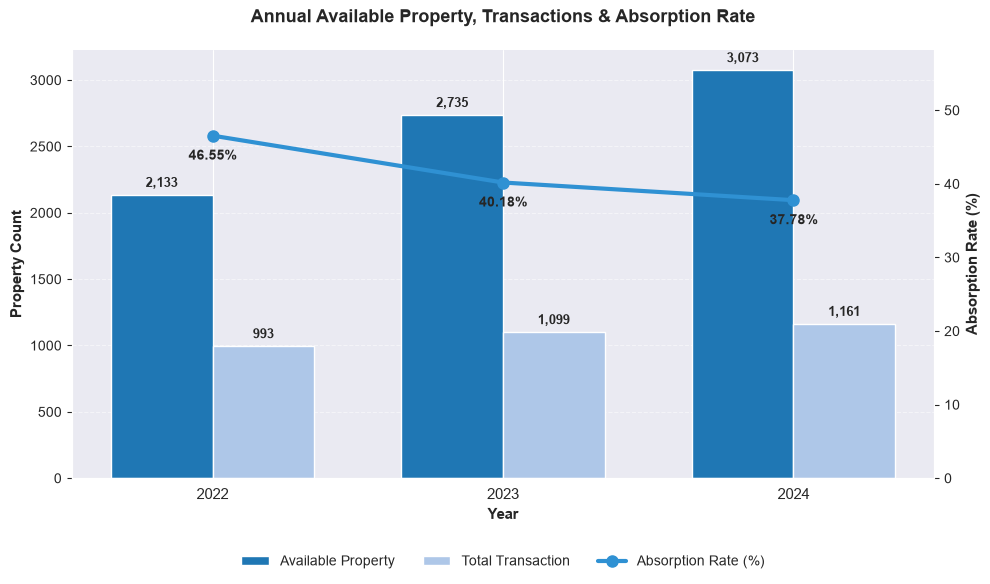

In [111]:
annual_available_property = []
years = (df_listing['listing_date'].dt.year).unique()

for year in years:
    start_date = pd.Timestamp(f'{year}-01-01')
    end_date = pd.Timestamp(f'{year}-12-31')

    historical_listings = df_listing[df_listing['listing_date'] < start_date]
    historical_ids = historical_listings['property_id'].unique()
    historical_sold = df_completed[df_completed['deal_date'] < start_date]
    historical_sold_ids = historical_sold['property_id'].unique()

    carry_over_prop_list = (
        df_listing[
            (df_listing['listing_date']<start_date)&
            ((df_listing['close_date']>=start_date)|
            (df_listing['listing_status']=='Active'))
        ]['property_id'].unique()
    )

    new_listing = (
        df_listing[
            (df_listing['listing_date']>=start_date)&
            (df_listing['listing_date']<=end_date)
        ]
    )
	
    new_listing_prop_id = new_listing['property_id'].unique()
	
    carry_over1 = np.intersect1d(new_listing_prop_id,carry_over_prop_list)
    carry_over2 = np.setdiff1d(carry_over_prop_list,carry_over1)
    CarOve_available = np.union1d(carry_over1,carry_over2)
    total_carry_over_prop = len(CarOve_available)
	
    new_prop_accu = np.setdiff1d(new_listing_prop_id,CarOve_available)
    total_new_prop_accu = len(new_prop_accu)

    avail_prop = np.union1d(CarOve_available,new_prop_accu)
	
    total_available_prop = total_new_prop_accu + total_carry_over_prop
    newest_prop_ids = np.setdiff1d(new_listing_prop_id,historical_ids)
    newest_prop = len(newest_prop_ids)
    renew_prop_id = np.setdiff1d(new_prop_accu,newest_prop_ids)
    renew_prop = len(renew_prop_id)

    completed_property = (
        df_completed[
            (df_completed['deal_date']>=start_date)&
            (df_completed['deal_date']<=end_date)
        ]
    )

    completed_property_id = completed_property['property_id'].unique()
    total_completed_property = len(completed_property_id)

    completed_duplicate_prop_id = completed_property[completed_property.duplicated(subset='property_id')]['property_id'].unique()

    annual_available_property.append(
        {'year': year,
        'total_carry_over_property' : total_carry_over_prop,
        'total_new_property' : total_new_prop_accu,
	    'total_newest_prop' :newest_prop,
	    'total_resell_prop' :renew_prop,
        'total_available_property': total_available_prop,
        'total_completed_property': total_completed_property,
        'total_prop_multiple trans' : len(completed_duplicate_prop_id)}
    )

annual_absorption_prop = pd.DataFrame(annual_available_property)
annual_absorption_prop = annual_absorption_prop.sort_values('year').reset_index(drop=True)
annual_absorption_prop['absorption_rate'] = (\
    annual_absorption_prop['total_completed_property']
    /annual_absorption_prop['total_available_property']*100).round(2)

display(annual_absorption_prop)

sns.set_style("darkgrid")
fig, ax1 = plt.subplots(figsize=(10, 6))

x = np.arange(len(annual_absorption_prop["year"]))
width = 0.35

rects1 = ax1.bar(\
    x - width / 2,
    annual_absorption_prop["total_available_property"],
    width,
    label="Available Property",
    color="#1f77b4",
)

rects2 = ax1.bar(\
    x + width / 2,
    annual_absorption_prop["total_completed_property"],
    width,
    label="Total Transaction",
    color="#aec7e8",
)

ax1.set_ylabel("Property Count", fontsize=11, fontweight="bold")
ax1.set_xlabel("Year", fontsize=11, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(annual_absorption_prop["year"].astype(str), fontsize=11)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

for rect in rects1 + rects2:
    height = rect.get_height()
    ax1.annotate(
        f"{int(height):,}",
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

ax2 = ax1.twinx()

line_color = "#2f91d3"

line = ax2.plot(\
    x,
    annual_absorption_prop["absorption_rate"],
    color=line_color,
    marker="o",
    linewidth=3,
    markersize=8,
    label="Absorption Rate (%)",
)

ax2.set_ylabel("Absorption Rate (%)", fontsize=11, fontweight="bold")
ax2.tick_params(axis="y")
ax2.grid(False)

max_rate = annual_absorption_prop["absorption_rate"].max()
ax2.set_ylim(0, max_rate * 1.25)

for i, txt in enumerate(annual_absorption_prop["absorption_rate"]):
    ax2.annotate(\
        f"{txt:.2f}%",
        (x[i], txt),
        textcoords="offset points",
        xytext=(0, -10),
        ha="center",
        va = 'top',
        fontweight="bold",
        fontsize=10,
    )

plt.title(
    "Annual Available Property, Transactions & Absorption Rate",
    fontsize=13,
    fontweight="bold",
    pad=20,
    loc="center",
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(\
    lines1 + lines2,
    labels1 + labels2,
    bbox_to_anchor=(0.5, -0.15),
    loc="upper center",
    ncol =3,
    frameon=True,
    facecolor="white",
    edgecolor="none",
)

sns.despine(top=True, right=False)
plt.tight_layout()
plt.show()



##
**Convertion Rate by Segment**

>Which segments have higher or lower conversion rates?

In [112]:
def call_analysis(df1, df2, df3, col):
    #Property Analisis
    total_prop = (
        df1.groupby(col)
        .agg(total_property=('property_id', 'nunique'))
        .reset_index()
    )
    
    total_trans = (
        df2.groupby(col)
        .agg(total_property_sold=('property_id', 'nunique'))
        .reset_index()
    )
    
    property_perform = total_prop.merge(total_trans, on=col, how='left').fillna(0)
    
    property_perform['prop_conversion_rate'] = round(
        (property_perform['total_property_sold'] /
          property_perform['total_property']) * 100, 2
    )
    property_perform = property_perform.sort_values('prop_conversion_rate',ascending = False).reset_index(drop=True)
    # Listing Analysis
    total_list = (
        df3.groupby(col)
        .agg(total_listing=('listing_id', 'nunique'))
        .reset_index()
    )
    
    total_trans_listing = (
        df2.groupby(col)
        .agg(total_listing_completed=('listing_id', 'nunique'),
             avg_DOM = ('days_on_market','mean'))
        .reset_index() 
    )
    total_trans_listing['avg_DOM'] = round(total_trans_listing['avg_DOM'],0)
    listing_perform = total_list.merge(total_trans_listing, on=col, how='left').fillna(0)
    
    listing_perform['listing_conversion_rate'] = round(
        (listing_perform['total_listing_completed'] / listing_perform['total_listing']) * 100, 2
    )
    
    listing_perform = listing_perform.sort_values('listing_conversion_rate',ascending=False).reset_index(drop = True)
    return property_perform, listing_perform



###
Conversion Rate by City

In [113]:
prop_city,list_city = call_analysis(df_listed_prop,df_completed,df_listing,'prop_city')
display(prop_city,list_city)

,prop_city,total_property,total_property_sold,prop_conversion_rate
0,Barishal,271,195,71.96
1,Sylhet,299,205,68.56
2,Dhaka,1118,746,66.73
3,Rajshahi,344,224,65.12
4,Chattogram,687,446,64.92
5,Mymensingh,344,222,64.53
6,Khulna,427,275,64.40
7,Rangpur,327,203,62.08


,prop_city,total_listing,total_listing_completed,avg_DOM,listing_conversion_rate
0,Barishal,612,287,44.0,46.90
1,Rajshahi,724,332,47.0,45.86
2,Sylhet,649,295,47.0,45.45
3,Dhaka,2527,1124,44.0,44.48
4,Chattogram,1575,678,44.0,43.05
5,Mymensingh,757,321,45.0,42.40
6,Khulna,959,406,46.0,42.34
7,Rangpur,697,294,44.0,42.18


###
Conversion Rate by Property Type

In [114]:
prop_proptype, list_proptype = call_analysis(df_listed_prop,df_completed,df_listing,'property_type')
display(prop_proptype,list_proptype)

,property_type,total_property,total_property_sold,prop_conversion_rate
0,Apartment,2098,1411,67.25
1,Land,410,267,65.12
2,Commercial,304,196,64.47
3,House,1005,642,63.88


,property_type,total_listing,total_listing_completed,avg_DOM,listing_conversion_rate
0,Apartment,4683,2127,43.0,45.42
1,House,2216,958,46.0,43.23
2,Land,906,372,48.0,41.06
3,Commercial,695,280,49.0,40.29


###
Coversion Rate by Channel

In [115]:
prop_chan,list_chan = call_analysis(df_listing,df_completed,df_listing,'listing_channel')
display(prop_chan,list_chan)


,listing_channel,total_property,total_property_sold,prop_conversion_rate
0,Open,2562,1409,55.00
1,Exclusive,2487,1330,53.48
2,Partner,968,457,47.21


,listing_channel,total_listing,total_listing_completed,avg_DOM,listing_conversion_rate
0,Partner,1069,478,44.0,44.71
1,Open,3826,1687,44.0,44.09
2,Exclusive,3605,1572,46.0,43.61


###
Conversion Rate by Price Category

In [116]:
prop_pricecat, list_pricecat = call_analysis(df_listing,df_completed,df_listing,'listed_price_cat')
display(prop_pricecat, list_pricecat)

,listed_price_cat,total_property,total_property_sold,prop_conversion_rate
0,cheap,3544,2330,65.74
1,medium,333,199,59.76
2,expensive,19,11,57.89


,listed_price_cat,total_listing,total_listing_completed,avg_DOM,listing_conversion_rate
0,cheap,7793,3448,45.0,44.24
1,medium,666,278,48.0,41.74
2,expensive,41,11,43.0,26.83


## 
**Conversion Rate by Property Characteristics**

> Which property characteristics are associated with higher property conversion?

Property Characteristics List = 

'property_size_cat', 'bedrooms', 'bathrooms', 

'location_score_cat', 'has_parking', 

'near_transit', 'near_school','list_price', 

'amenities_count'

In [117]:
columns = ['property_size_cat', 'bedrooms', 'bathrooms','location_score_cat', 
           'has_parking', 'near_transit', 'near_school', 'amenities_count']
property_perform = {}

for col in columns:
    total_prop = (
        df_properties
        .groupby(col)
        .agg(total_property=('property_id', 'nunique'))
        .reset_index()
    )
    
    total_trans = (
        df_completed.groupby(col)
        .agg(total_property_sold=('property_id', 'nunique'))
        .reset_index()
    )
    
    property_perform[col] = total_prop.merge(total_trans, on=col, how='left').fillna(0)
    
    property_perform[col]['conversion_rate'] = round(
        (property_perform[col]['total_property_sold'] /
          property_perform[col]['total_property']) * 100, 2
    )

    property_perform[col] = property_perform[col].sort_values('conversion_rate',ascending=False).reset_index(drop=True)
for col, df_result in property_perform.items():
        print(f"---Property Conversion Rate by {col}---")
        display(df_result)
        print("\n")


---Property Conversion Rate by property_size_cat---


,property_size_cat,total_property,total_property_sold,conversion_rate
0,medium,357,206,57.70
1,small,4133,2305,55.77
2,large,10,5,50.00




---Property Conversion Rate by bedrooms---


,bedrooms,total_property,total_property_sold,conversion_rate
0,2,1243,706,56.80
1,4,536,303,56.53
2,3,1207,682,56.50
3,1,463,259,55.94
4,5,117,65,55.56
5,0,919,493,53.65
6,6,15,8,53.33




---Property Conversion Rate by bathrooms---


...

,near_transit,total_property,total_property_sold,conversion_rate
0,True,2276,1288,56.59
1,False,2224,1228,55.22




---Property Conversion Rate by near_school---


,near_school,total_property,total_property_sold,conversion_rate
0,True,2287,1283,56.10
1,False,2213,1233,55.72




---Property Conversion Rate by amenities_count---


,amenities_count,total_property,total_property_sold,conversion_rate
0,12.0,160,101,63.12
1,3.0,152,92,60.53
2,8.0,854,503,58.90
3,11.0,261,152,58.24
4,5.0,426,244,57.28
5,7.0,642,362,56.39
6,6.0,535,294,54.95
7,14.0,33,18,54.55
8,4.0,255,139,54.51
9,9.0,541,290,53.60


##
**Agent Coverage and Property Conversion Rate**

How does the number of agents assigned to a property relate to its conversion performance?

In [118]:
df_agent = df_dataset.groupby('agent_id').agg(total_list_props_handled = ('property_id','nunique'),
                                              median_DOM = ('days_on_market','median'))
df_agent['property_sold'] = df_completed.groupby('agent_id')['transaction_id'].nunique()
df_agent['total_earning'] = df_completed.groupby('agent_id')['deal_price'].sum()
df_agent['conversion_rate'] = round((df_agent['property_sold']/df_agent['total_list_props_handled'])*100,2)
df_agent['market_share'] = round((df_agent['property_sold']/(df_agent['property_sold'].sum()))*100,2)
df_agent['revenue_share'] = round((df_agent['total_earning']/(df_agent['total_earning'].sum()))*100,2)
df_agent = df_agent.sort_values(['conversion_rate', 'median_DOM'], ascending=[False, True]).reset_index()
df_agent


,agent_id,total_list_props_handled,median_DOM,property_sold,total_earning,conversion_rate,market_share,revenue_share
0,A00177,21,50.0,14,148948885.0,66.67,0.37,0.29
1,A00114,21,51.0,14,213441053.0,66.67,0.37,0.41
2,A00098,23,44.0,15,182821664.0,65.22,0.40,0.35
3,A00244,23,56.0,15,194127502.0,65.22,0.40,0.38
4,A00049,27,56.5,17,258263954.0,62.96,0.45,0.50
...,...,...,...,...,...,...,...,...
295,A00051,29,76.0,7,86949425.0,24.14,0.19,0.17
296,A00249,30,71.0,7,113104518.0,23.33,0.19,0.22
297,A00058,26,72.5,6,88414695.0,23.08,0.16,0.17
298,A00011,28,68.0,6,81514708.0,21.43,0.16,0.16


In [119]:
df_agent_perform = df_agent.copy()
df_agent_perform = (
    df_agent_perform
    .groupby('total_list_props_handled')
    .agg(num_of_agents = ('agent_id','nunique'),
        avg_conversion_rate = ('conversion_rate','mean'))
    .sort_values('num_of_agents',ascending = False)
    .reset_index()
)
df_agent_perform= (df_agent_perform[['num_of_agents','total_list_props_handled' ,'avg_conversion_rate']]
                   .sort_values('avg_conversion_rate',ascending = False)
                   .reset_index(drop=True)
)
df_agent_perform

,num_of_agents,total_list_props_handled,avg_conversion_rate
0,9,21,54.497778
1,2,38,50.000000
2,5,20,48.000000
3,2,43,47.675000
4,6,36,47.223333
5,17,33,46.878235
6,26,32,46.393846
7,19,31,46.350000
8,23,29,46.327391
9,21,23,44.513810


In [120]:
df_property = df_listing.copy()
df_property['num_agent_handling'] = df_property.groupby('property_id')['agent_id'].transform('nunique')
df_property =  df_property.drop_duplicates(subset ='property_id')
df_property = df_property[['property_id','num_agent_handling']]


df_prop_sold = df_completed.copy()
df_prop_sold['num_trans_prop'] = df_prop_sold.groupby('property_id')['transaction_id'].transform('nunique')
df_prop_sold = df_prop_sold.drop_duplicates(subset='property_id')
df_prop_sold = df_prop_sold[['property_id','num_trans_prop']]


df_dataprop = df_property.merge(df_prop_sold,on = 'property_id',how = 'left')
df_agent_perform = (
    df_dataprop
    .groupby('num_agent_handling')
    .agg(total_properties_handled = ('property_id','count'),
        total_sold = ('num_trans_prop','count')).reset_index()
)

df_agent_perform['conversion_rate'] = round((df_agent_perform['total_sold']/df_agent_perform['total_properties_handled'])*100,2)
df_agent_perform = (df_agent_perform[['total_properties_handled','num_agent_handling','total_sold','conversion_rate']]
                    .sort_values('conversion_rate',ascending = False)
                    .reset_index(drop=True)
)
df_agent_perform

,total_properties_handled,num_agent_handling,total_sold,conversion_rate
0,1,9,1,100.00
1,15,7,15,100.00
2,3,8,3,100.00
3,50,6,50,100.00
4,132,5,124,93.94
5,336,4,305,90.77
6,768,3,622,80.99
7,1225,2,831,67.84
8,1287,1,565,43.90


##
**Unsold/Aging Metrics**

>Which properties or property segments are underperforming in terms of conversion?

###
Unsold Property Overview

In [121]:
df_active_listing = (
    df_listing[
        (df_listing['listing_status']=='Active')|
        (df_listing['close_date'].dt.year >=2025)]
        .reset_index(drop=True)
)
df_prop_active_list = df_active_listing.drop_duplicates(subset = 'property_id')

id_unsold_prop = df_prop_active_list['property_id']
id_sold_prop = df_transaction['property_id'].unique()

resell_prop = np.intersect1d(id_unsold_prop,id_sold_prop)

print(f'Number of Listing Aging = {len(df_active_listing)}')
print(f'Number of Unsold Property = {len(df_prop_active_list)}')
print(f'Number of Resell Property = {len(resell_prop)}')

Number of Listing Aging = 3125
Number of Unsold Property = 2082
Number of Resell Property = 815


###
Unsold Property by Segment

In [122]:
columns = ['prop_city','property_type','listing_channel','listed_price_cat']
unsold_property = {}

for col in columns:
    
    data = (df_prop_active_list
            .groupby(col)
            .agg(total_property_unsold = ('property_id','count')) 
            .reset_index()
    )
    
    unsold_property[col] = (
        data
        .sort_values('total_property_unsold',ascending=False)
        .reset_index(drop=True)
    )

for col, df_result in unsold_property.items():
        print(f"---Unsold Property by {col}---")
        display(df_result)


---Unsold Property by prop_city---


,prop_city,total_property_unsold
0,Dhaka,610
1,Chattogram,393
2,Khulna,241
3,Mymensingh,189
4,Rangpur,186
5,Rajshahi,170
6,Sylhet,156
7,Barishal,137


---Unsold Property by property_type---


,property_type,total_property_unsold
0,Apartment,1124
1,House,560
2,Land,229
3,Commercial,169


---Unsold Property by listing_channel---


,listing_channel,total_property_unsold
0,Open,911
1,Exclusive,909
2,Partner,262


---Unsold Property by listed_price_cat---


,listed_price_cat,total_property_unsold
0,cheap,1916
1,medium,158
2,expensive,8


###
Listing Aging Bucket


| Days Active  | Category          | Interpretation                                                                                                                           |
| ------------ | ----------------- | ---------------------------------------------------------------------------------------------------------------------------------------- |
| 0–90 days    | Fresh/New Listing | Newly added listings that are still within the initial marketing period and have higher potential to attract buyer interest.             |
| 91–180 days  | Normal Exposure   | Properties that remain within a reasonable market exposure period and are still considered actively marketable.                          |
| 181–365 days | Aging Listing     | Listings that require evaluation of pricing strategy, property positioning, and marketing efforts due to longer time on the market.      |
| 366–730 days | Long-Term Listing | Older listings that indicate slower sales movement and may reduce listing turnover and sales efficiency.                                 |
| >730 days    | Stale Listing     | Highly aged listings with a higher risk of remaining unsold, requiring significant strategy adjustments to improve conversion potential. |


In [139]:
bins = [
    0,
    90,
    180,
    365,
    730,
    float('inf')
]

category = [
    'Fresh/New Listing',
    'Normal Exposure',
    'Aging Listing',
    'Long-Term Listing',
    'Stale Listing'
]

df_active_listing['active_status'] = (\
    pd.cut(df_active_listing['days_on_market'],
           bins,
           labels = category,
           include_lowest = True)
)

listing_aging_prop = (\
    df_active_listing
    .groupby('active_status')
    .agg(total_property = ('property_id','nunique'))
)
listing_aging_prop['property_share'] = (
    round((listing_aging_prop['total_property']/
           (listing_aging_prop['total_property'].sum()))*100,2)
)

listing_aging_prop = listing_aging_prop.sort_values('property_share',ascending = False)
listing_aging_prop = listing_aging_prop.reset_index()
listing_aging_prop

,active_status,total_property,property_share
0,Fresh/New Listing,1258,47.91
1,Normal Exposure,1174,44.71
2,Aging Listing,194,7.39


In [124]:
def call_crosstab (df,col1,col2,col3):
   df_crosstab = pd.crosstab(
                                    df[col1]
                                    ,df[col2]
                                    ,values=df[col3]
                                    ,aggfunc='nunique')

   return(df_crosstab)

In [125]:
columns = ['prop_city','property_type','listing_channel','listed_price_cat']
aging_share = {}

for col in columns:
    
    data = call_crosstab(df_active_listing,col,'active_status','property_id')
    
    aging_share[col] = data

for col, df_result in aging_share.items():
        print(f"{'-'*20} Aging Share by {col} {'-'*20}")
        display(df_result)

-------------------- Aging Share by prop_city --------------------


active_status,Fresh/New Listing,Normal Exposure,Aging Listing
prop_city,,,
Barishal,79,76,15
Chattogram,226,237,36
Dhaka,385,330,50
Khulna,144,144,21
Mymensingh,119,102,21
Rajshahi,95,100,14
Rangpur,119,103,18
Sylhet,91,82,19


-------------------- Aging Share by property_type --------------------


active_status,Fresh/New Listing,Normal Exposure,Aging Listing
property_type,,,
Apartment,716,616,73
Commercial,100,94,23
House,307,330,64
Land,135,134,34


-------------------- Aging Share by listing_channel --------------------


active_status,Fresh/New Listing,Normal Exposure,Aging Listing
listing_channel,,,
Exclusive,593,552,90
Open,621,590,84
Partner,189,168,25


-------------------- Aging Share by listed_price_cat --------------------


active_status,Fresh/New Listing,Normal Exposure,Aging Listing
listed_price_cat,,,
cheap,1160,1091,170
medium,99,85,24
expensive,6,4,1


###
Active Listing by Agent

In [126]:
df_agent_actv_list = (
    df_active_listing
    .groupby('agent_id')
    .agg(total_listing_active = ('listing_id','nunique'))
    .reset_index()
)

df_agent = df_agent.merge(df_agent_actv_list,on='agent_id',how = 'left')
df_agent

,agent_id,total_list_props_handled,median_DOM,property_sold,total_earning,conversion_rate,market_share,revenue_share,total_listing_active
0,A00177,21,50.0,14,148948885.0,66.67,0.37,0.29,3
1,A00114,21,51.0,14,213441053.0,66.67,0.37,0.41,7
2,A00098,23,44.0,15,182821664.0,65.22,0.40,0.35,6
3,A00244,23,56.0,15,194127502.0,65.22,0.40,0.38,2
4,A00049,27,56.5,17,258263954.0,62.96,0.45,0.50,9
...,...,...,...,...,...,...,...,...,...
295,A00051,29,76.0,7,86949425.0,24.14,0.19,0.17,14
296,A00249,30,71.0,7,113104518.0,23.33,0.19,0.22,18
297,A00058,26,72.5,6,88414695.0,23.08,0.16,0.17,7
298,A00011,28,68.0,6,81514708.0,21.43,0.16,0.16,15


##
Transaction Value & Commission by Segment

Which property segments generate the highest transaction value and commission?

In [127]:
columns = ['prop_city','property_type','listing_channel','listed_price_cat']
revenue_performance = {}

for col in columns:
    
    data = (df_completed
            .groupby(col)
            .agg(total_revenue = ('deal_price','sum'),
                 total_agent_commission=('commission_amount','sum'))
            .reset_index()
    )

    data['revenue_share'] = (
          round(
                (data['total_revenue']/
                 (data['total_revenue'].sum())
                 )*100,2
          )
    )
    revenue_performance[col] = (
        data
        .sort_values('total_revenue',ascending=False)
        .reset_index(drop=True)
    )

for col, df_result in revenue_performance.items():
        print(f"---Revenue Performance by {col}---")
        display(df_result)


---Revenue Performance by prop_city---


,prop_city,total_revenue,total_agent_commission,revenue_share
0,Dhaka,2.107547e+10,525000481.0,40.89
1,Chattogram,1.002952e+10,247645668.0,19.46
2,Khulna,4.370173e+09,107485376.0,8.48
3,Mymensingh,3.611587e+09,89259750.0,7.01
4,Sylhet,3.525160e+09,86495450.0,6.84
5,Rajshahi,3.392819e+09,83865848.0,6.58
6,Rangpur,2.876720e+09,70406973.0,5.58
7,Barishal,2.660260e+09,65827274.0,5.16


---Revenue Performance by property_type---


,property_type,total_revenue,total_agent_commission,revenue_share
0,Apartment,2.172824e+10,536479553.0,42.16
1,House,1.779648e+10,440424950.0,34.53
2,Commercial,7.208457e+09,181869564.0,13.99
3,Land,4.808529e+09,117212753.0,9.33


---Revenue Performance by listing_channel---


,listing_channel,total_revenue,total_agent_commission,revenue_share
0,Open,2.331081e+10,579371927.0,45.23
1,Exclusive,2.184554e+10,540743195.0,42.38
2,Partner,6.385356e+09,155871698.0,12.39


---Revenue Performance by listed_price_cat---


,listed_price_cat,total_revenue,total_agent_commission,revenue_share
0,cheap,4.180124e+10,1.031358e+09,81.10
1,medium,9.120170e+09,2.281255e+08,17.69
2,expensive,6.202992e+08,1.650346e+07,1.20


##
**Segment Resume Performance**

In [128]:

def resume_segment (list_df, prop_df, revenue_df, unsold_df, on_col):
    performance_df = (
        list_df
        .merge(prop_df, on=on_col, how='left')
        .merge(revenue_df, on=on_col, how='left')
        .merge(unsold_df, on=on_col, how='left')
    )
    
    desired_columns = [
        on_col, 'listing_conversion_rate', 'avg_DOM', 'prop_conversion_rate',
        'revenue_share', 'total_property_unsold', 'total_listing', 
        'total_listing_completed', 'total_property', 'total_property_sold',
        'total_revenue', 'total_agent_commission'
    ]
    
    existing_columns = [col for col in desired_columns if col in performance_df.columns]
    
    performance_df = (
        performance_df[existing_columns]
        .sort_values('prop_conversion_rate', ascending=False)
        .reset_index(drop=True)
    )
    
    return performance_df

###
City

In [129]:
df_unsold_property_city = unsold_property['prop_city']
df_revenue_performance_city = revenue_performance['prop_city']
city_performance = resume_segment(prop_city,list_city,df_revenue_performance_city,df_unsold_property_city,'prop_city')
city_performance

,prop_city,listing_conversion_rate,avg_DOM,prop_conversion_rate,revenue_share,total_property_unsold,total_listing,total_listing_completed,total_property,total_property_sold,total_revenue,total_agent_commission
0,Barishal,46.90,44.0,71.96,5.16,137,612,287,271,195,2.660260e+09,65827274.0
1,Sylhet,45.45,47.0,68.56,6.84,156,649,295,299,205,3.525160e+09,86495450.0
2,Dhaka,44.48,44.0,66.73,40.89,610,2527,1124,1118,746,2.107547e+10,525000481.0
3,Rajshahi,45.86,47.0,65.12,6.58,170,724,332,344,224,3.392819e+09,83865848.0
4,Chattogram,43.05,44.0,64.92,19.46,393,1575,678,687,446,1.002952e+10,247645668.0
5,Mymensingh,42.40,45.0,64.53,7.01,189,757,321,344,222,3.611587e+09,89259750.0
6,Khulna,42.34,46.0,64.40,8.48,241,959,406,427,275,4.370173e+09,107485376.0
7,Rangpur,42.18,44.0,62.08,5.58,186,697,294,327,203,2.876720e+09,70406973.0


###
Property Type

In [130]:
df_unsold_property_proptype = unsold_property['property_type']
df_revenue_performance_proptype = revenue_performance['property_type']

proprtype_performance = resume_segment(prop_proptype, list_proptype,df_revenue_performance_proptype,df_unsold_property_proptype,'property_type')
proprtype_performance

,property_type,listing_conversion_rate,avg_DOM,prop_conversion_rate,revenue_share,total_property_unsold,total_listing,total_listing_completed,total_property,total_property_sold,total_revenue,total_agent_commission
0,Apartment,45.42,43.0,67.25,42.16,1124,4683,2127,2098,1411,2.172824e+10,536479553.0
1,Land,41.06,48.0,65.12,9.33,229,906,372,410,267,4.808529e+09,117212753.0
2,Commercial,40.29,49.0,64.47,13.99,169,695,280,304,196,7.208457e+09,181869564.0
3,House,43.23,46.0,63.88,34.53,560,2216,958,1005,642,1.779648e+10,440424950.0


###
Listing Channel

In [131]:
df_unsold_property_channel = unsold_property['listing_channel']
df_revenue_performance_channel = revenue_performance['listing_channel']

channel_performance = resume_segment(prop_chan,list_chan,df_revenue_performance_channel,df_unsold_property_channel,'listing_channel')
channel_performance

,listing_channel,listing_conversion_rate,avg_DOM,prop_conversion_rate,revenue_share,total_property_unsold,total_listing,total_listing_completed,total_property,total_property_sold,total_revenue,total_agent_commission
0,Open,44.09,44.0,55.00,45.23,911,3826,1687,2562,1409,2.331081e+10,579371927.0
1,Exclusive,43.61,46.0,53.48,42.38,909,3605,1572,2487,1330,2.184554e+10,540743195.0
2,Partner,44.71,44.0,47.21,12.39,262,1069,478,968,457,6.385356e+09,155871698.0


###
Listing Price Category

In [132]:
df_unsold_property_pricecat = unsold_property['listed_price_cat']
df_revenue_performance_pricecat = revenue_performance['listed_price_cat']

PriceCat_performance = resume_segment(prop_pricecat, list_pricecat,df_revenue_performance_pricecat,df_unsold_property_pricecat,'listed_price_cat')

PriceCat_performance

,listed_price_cat,listing_conversion_rate,avg_DOM,prop_conversion_rate,revenue_share,total_property_unsold,total_listing,total_listing_completed,total_property,total_property_sold,total_revenue,total_agent_commission
0,cheap,44.24,45.0,65.74,81.10,1916,7793,3448,3544,2330,4.180124e+10,1.031358e+09
1,medium,41.74,48.0,59.76,17.69,158,666,278,333,199,9.120170e+09,2.281255e+08
2,expensive,26.83,43.0,57.89,1.20,8,41,11,19,11,6.202992e+08,1.650346e+07


##
Underperformance Properties

In [133]:
df_active_prop = df_active_listing.copy()
df_active_prop['avg_DOM'] = df_active_prop.groupby('property_id')['days_on_market'].transform('mean')
df_active_prop['number_of_listing'] = df_active_prop.groupby('property_id')['listing_id'].transform('count')
df_active_prop = df_active_prop[['property_id','listed_price','prop_city','property_type','listed_price_cat','avg_DOM', 'number_of_listing']]
df_active_prop = df_active_prop.drop_duplicates(subset='property_id').sort_values(['avg_DOM','listed_price'],ascending=False).reset_index(drop=True)
df_active_prop.sort_values('property_id')

,property_id,listed_price,prop_city,property_type,listed_price_cat,avg_DOM,number_of_listing
531,P000007,7972626.0,Rangpur,Apartment,cheap,126.0,3
664,P000008,9023675.0,Chattogram,Apartment,cheap,116.0,1
928,P000010,14645973.0,Barishal,House,cheap,99.5,2
1958,P000011,9427022.0,Dhaka,Apartment,cheap,19.0,1
1803,P000015,11031136.0,Dhaka,Apartment,cheap,45.0,1
...,...,...,...,...,...,...,...
1005,P004487,18878698.0,Rangpur,House,cheap,95.0,1
1140,P004489,8000146.0,Rajshahi,Apartment,cheap,88.0,1
1458,P004494,9885397.0,Mymensingh,Apartment,cheap,70.0,2
318,P004497,9611835.0,Khulna,Apartment,cheap,145.0,1
